In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [81]:
df=pd.read_csv("/content/kidney_disease.csv")

In [82]:
df.head(20)

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd
5,5,60.0,90.0,1.015,3.0,0.0,NaN,NaN,notpresent,notpresent,...,39,7800,4.4,yes,yes,no,good,yes,no,ckd
6,6,68.0,70.0,1.010,0.0,0.0,NaN,normal,notpresent,notpresent,...,36,NaN,NaN,no,no,no,good,no,no,ckd
7,7,24.0,NaN,1.015,2.0,4.0,normal,abnormal,notpresent,notpresent,...,44,6900,5,no,yes,no,good,yes,no,ckd
8,8,52.0,100.0,1.015,3.0,0.0,normal,abnormal,present,notpresent,...,33,9600,4.0,yes,yes,no,good,no,yes,ckd
9,9,53.0,90.0,1.020,2.0,0.0,abnormal,abnormal,present,notpresent,...,29,12100,3.7,yes,yes,no,poor,no,yes,ckd


In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    object 
 17  wc              295 non-null    obj

In [84]:
df.describe()

,id,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo
count,400.000000,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,199.500000,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,115.614301,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,0.000000,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,99.750000,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,199.500000,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,299.250000,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,399.000000,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


In [85]:
df.dtypes

,0
id,int64
age,float64
bp,float64
sg,float64
al,float64
su,float64
rbc,object
pc,object
pcc,object
ba,object


In [86]:
# Remove unwanted spaces from all object columns

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

In [87]:
import numpy as np

df.replace('?', np.nan, inplace=True)

In [88]:
df['pcv'] = pd.to_numeric(df['pcv'], errors='coerce')

df['wc'] = pd.to_numeric(df['wc'], errors='coerce')

df['rc'] = pd.to_numeric(df['rc'], errors='coerce')

In [89]:
df.dtypes

,0
id,int64
age,float64
bp,float64
sg,float64
al,float64
su,float64
rbc,object
pc,object
pcc,object
ba,object


In [90]:
df.select_dtypes(include=['object']).dtypes

,0
rbc,object
pc,object
pcc,object
ba,object
htn,object
dm,object
cad,object
appet,object
pe,object
ane,object


In [91]:
# Remove spaces and tabs
for col in ['pcv', 'wc', 'rc']:
    df[col] = df[col].astype(str).str.strip()

# Convert into numeric datatype
df['pcv'] = pd.to_numeric(df['pcv'], errors='coerce')
df['wc'] = pd.to_numeric(df['wc'], errors='coerce')
df['rc'] = pd.to_numeric(df['rc'], errors='coerce')

In [92]:
print(df[['pcv', 'wc', 'rc']].dtypes)

pcv    float64
wc     float64
rc     float64
dtype: object


In [93]:
df.select_dtypes(include=['object']).dtypes

,0
rbc,object
pc,object
pcc,object
ba,object
htn,object
dm,object
cad,object
appet,object
pe,object
ane,object


In [94]:
df.dtypes

,0
id,int64
age,float64
bp,float64
sg,float64
al,float64
su,float64
rbc,object
pc,object
pcc,object
ba,object


In [95]:
df.isnull().sum()

,0
id,0
age,9
bp,12
sg,47
al,46
su,49
rbc,152
pc,65
pcc,4
ba,4


In [96]:
# Remove unwanted spaces from categorical columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Replace invalid missing value symbols
df.replace(['?', '\t?', ''], np.nan, inplace=True)

In [97]:
numeric_columns = ['pcv', 'wc', 'rc']

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [98]:
# Numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Categorical columns
cat_cols = df.select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(list(num_cols))

print("\nCategorical Columns:")
print(list(cat_cols))

Numerical Columns:
['id', 'age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']

Categorical Columns:
['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'classification']


In [99]:
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [100]:
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [101]:
# Check missing values after filling
print(df.isnull().sum())

# Total missing values
print("Total Missing Values:", df.isnull().sum().sum())

id                0
age               0
bp                0
sg                0
al                0
su                0
rbc               0
pc                0
pcc               0
ba                0
bgr               0
bu                0
sc                0
sod               0
pot               0
hemo              0
pcv               0
wc                0
rc                0
htn               0
dm                0
cad               0
appet             0
pe                0
ane               0
classification    0
dtype: int64
Total Missing Values: 0


In [102]:
df.shape

(400, 26)

In [103]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
395,False
396,False
397,False
398,False


array([[<Axes: title={'center': 'id'}>, <Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'bp'}>, <Axes: title={'center': 'sg'}>],
       [<Axes: title={'center': 'al'}>, <Axes: title={'center': 'su'}>,
        <Axes: title={'center': 'bgr'}>, <Axes: title={'center': 'bu'}>],
       [<Axes: title={'center': 'sc'}>, <Axes: title={'center': 'sod'}>,
        <Axes: title={'center': 'pot'}>,
        <Axes: title={'center': 'hemo'}>],
       [<Axes: title={'center': 'pcv'}>, <Axes: title={'center': 'wc'}>,
        <Axes: title={'center': 'rc'}>, <Axes: >]], dtype=object)

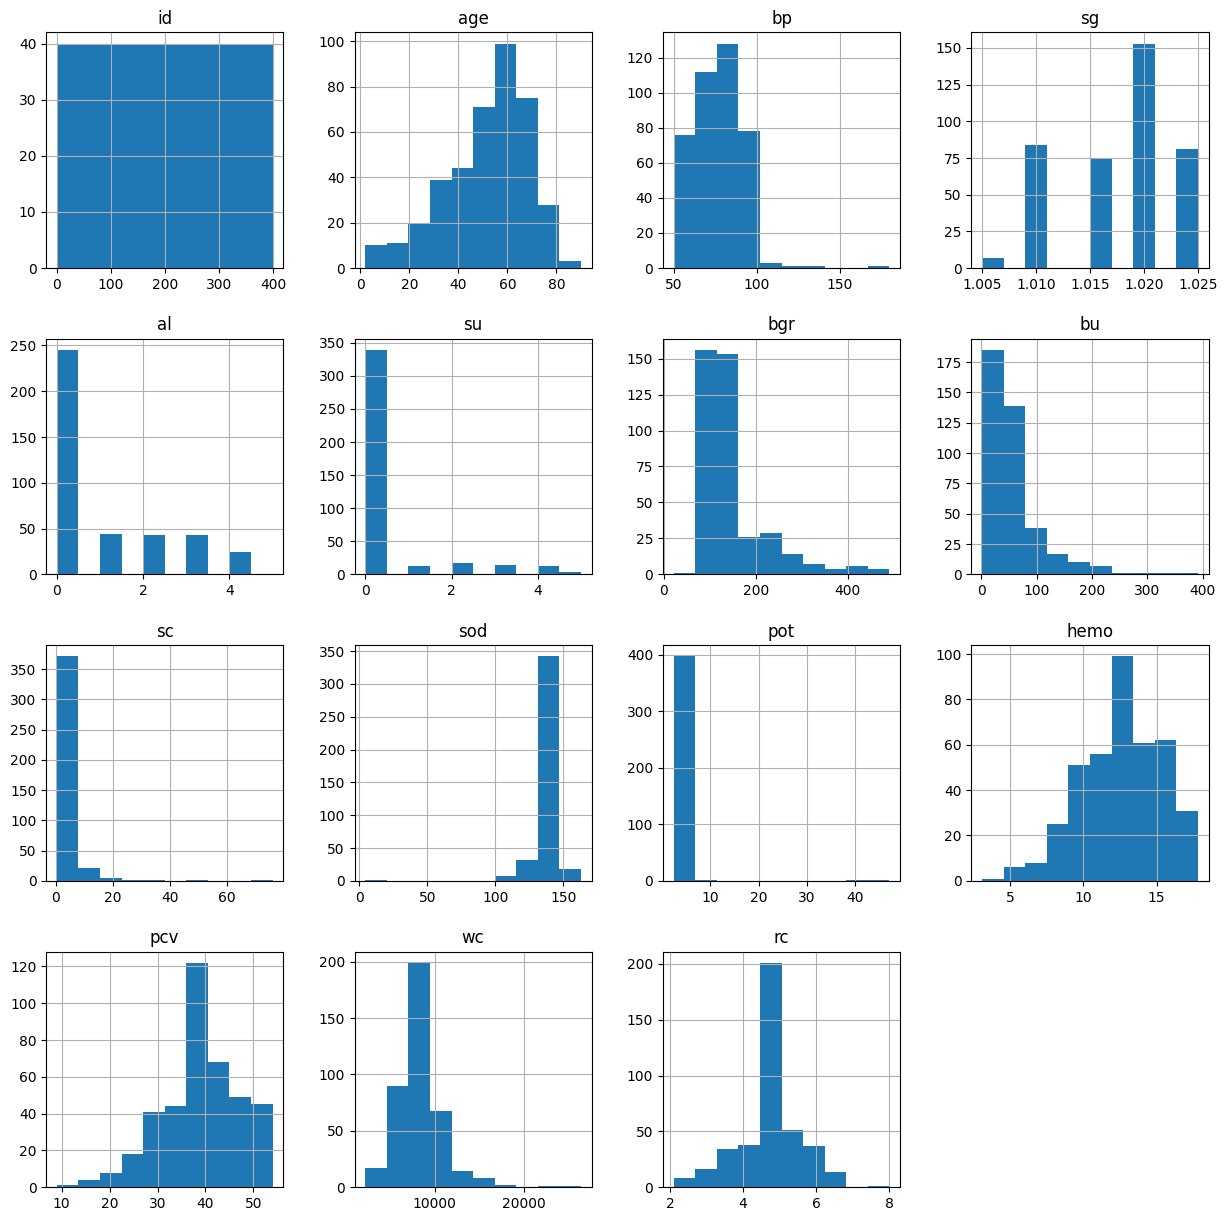

In [104]:
df.hist(figsize=(15, 15))

In [105]:
df.skew(numeric_only=True)

,0
id,0.000000
age,-0.688736
bp,1.601858
sg,-0.333320
al,1.180088
su,2.700055
bgr,2.204143
bu,2.724138
sc,7.665610
sod,-7.929336


In [106]:
# Select numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Apply log1p transformation
for col in num_cols:
    if df[col].skew() > 1:
        df[col] = np.log1p(df[col])

In [107]:
print("Skewness after Log Transformation:")
print(df.skew(numeric_only=True))

Skewness after Log Transformation:
id      0.000000
age    -0.688736
bp      0.424615
sg     -0.333320
al      0.800814
su      2.262984
bgr     0.911731
bu      0.413986
sc      1.679464
sod    -7.929336
pot     6.352954
hemo   -0.376747
pcv    -0.548541
wc     -0.126307
rc     -0.330485
dtype: float64


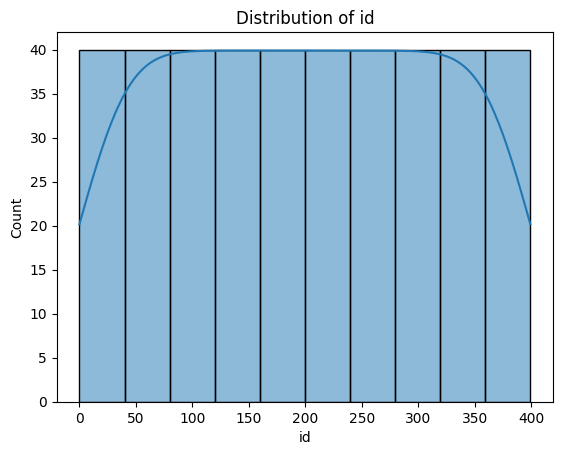

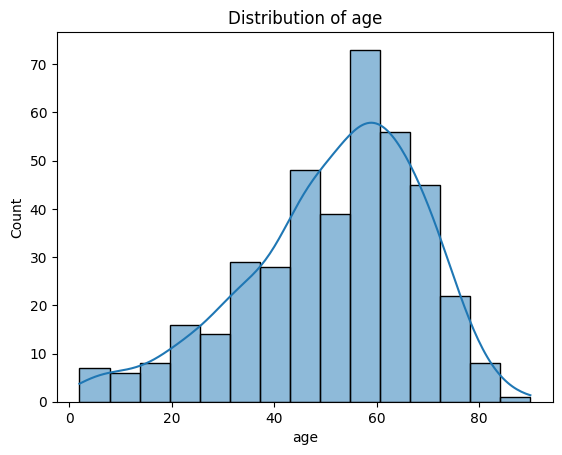

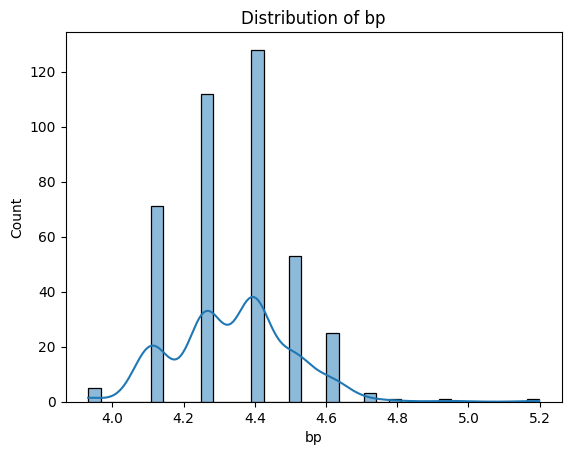

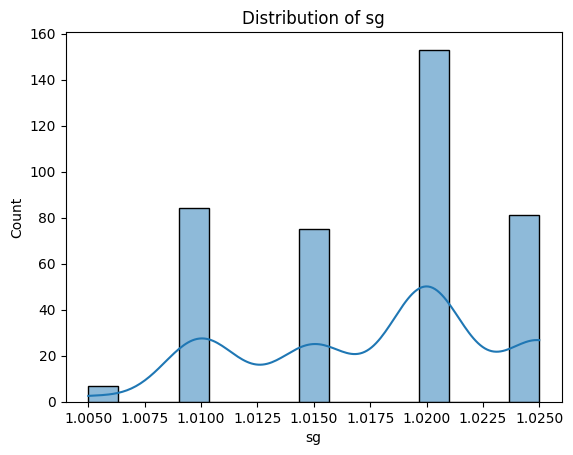

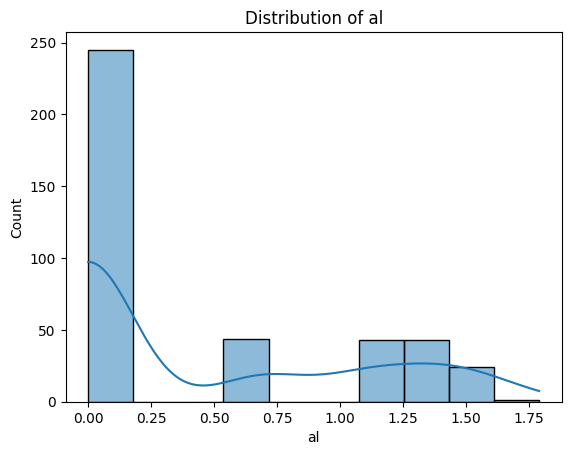

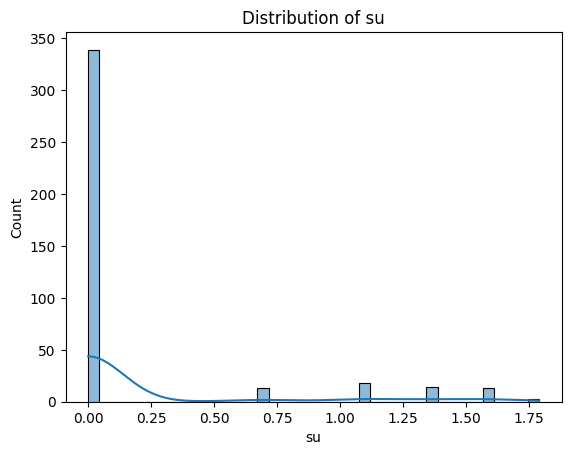

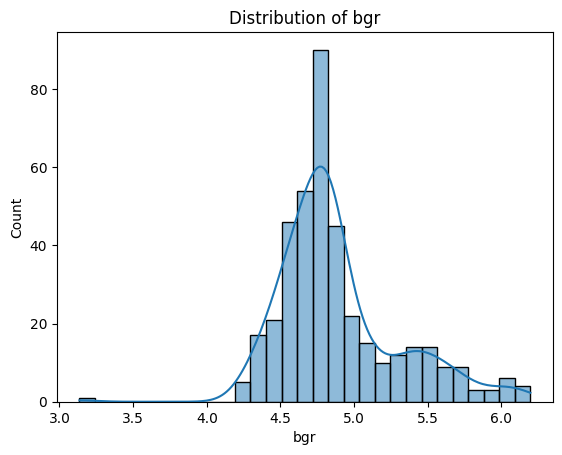

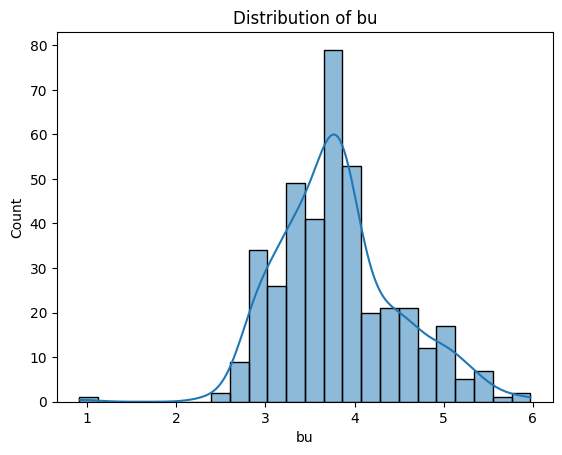

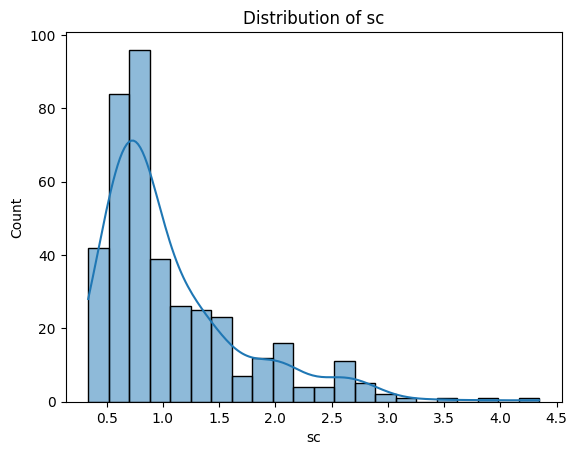

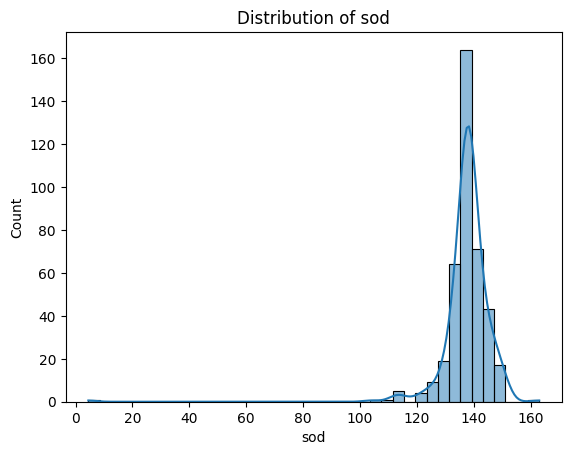

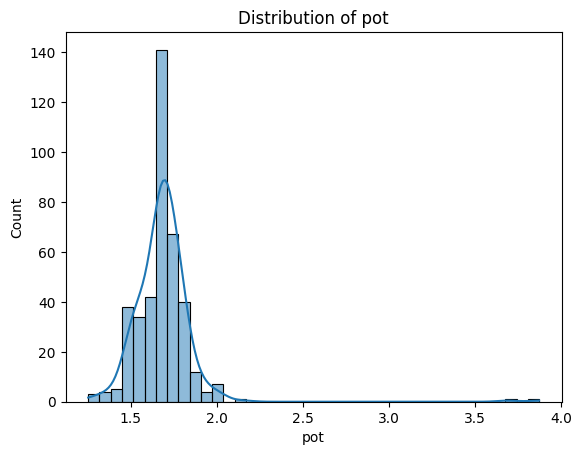

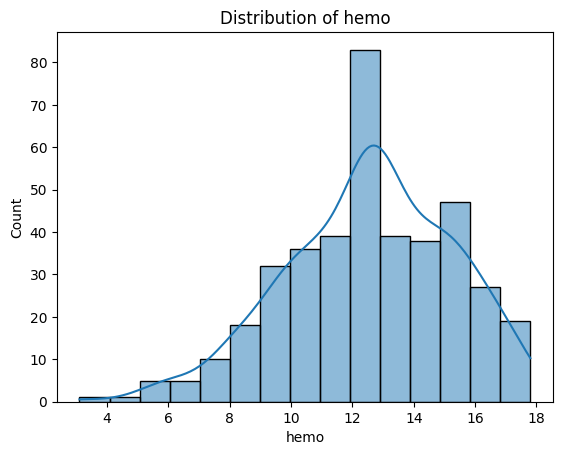

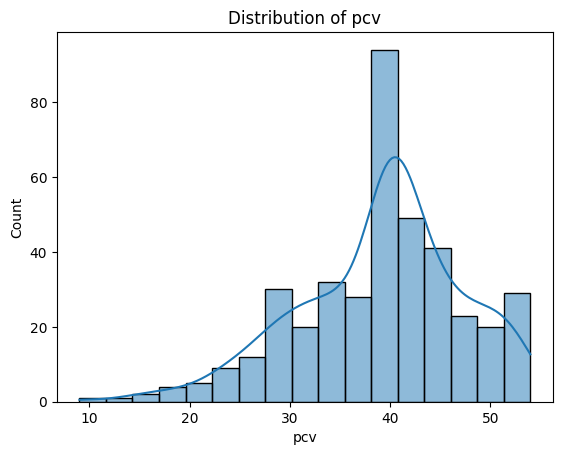

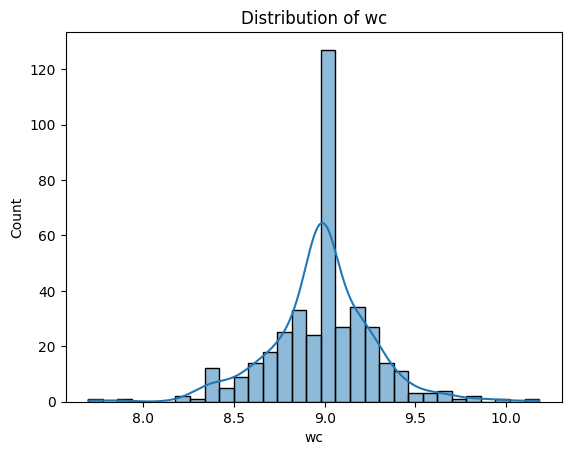

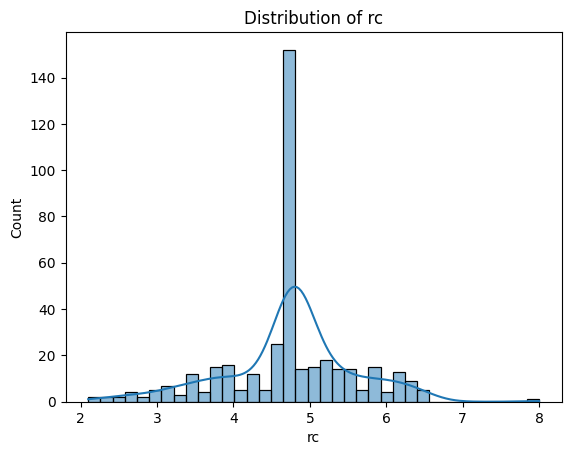

In [108]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in num_cols:
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

<Axes: >

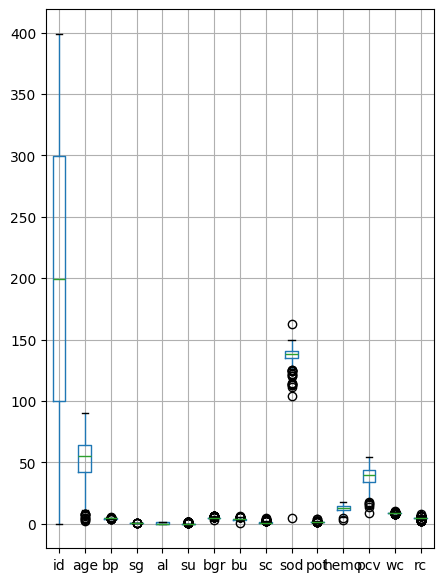

In [109]:
df.boxplot(figsize=(5,7))

In [110]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {outlier_count} outliers")

id: 0 outliers
age: 10 outliers
bp: 36 outliers
sg: 7 outliers
al: 0 outliers
su: 61 outliers
bgr: 29 outliers
bu: 10 outliers
sc: 27 outliers
sod: 18 outliers
pot: 19 outliers
hemo: 2 outliers
pcv: 6 outliers
wc: 24 outliers
rc: 75 outliers


In [111]:
cols_to_cap=["bp","su","bgr","sc","sod","pot","wc","rc"]

In [112]:
# Correctly cap the outliers in-place
for col in cols_to_cap:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower, upper)

<Axes: >

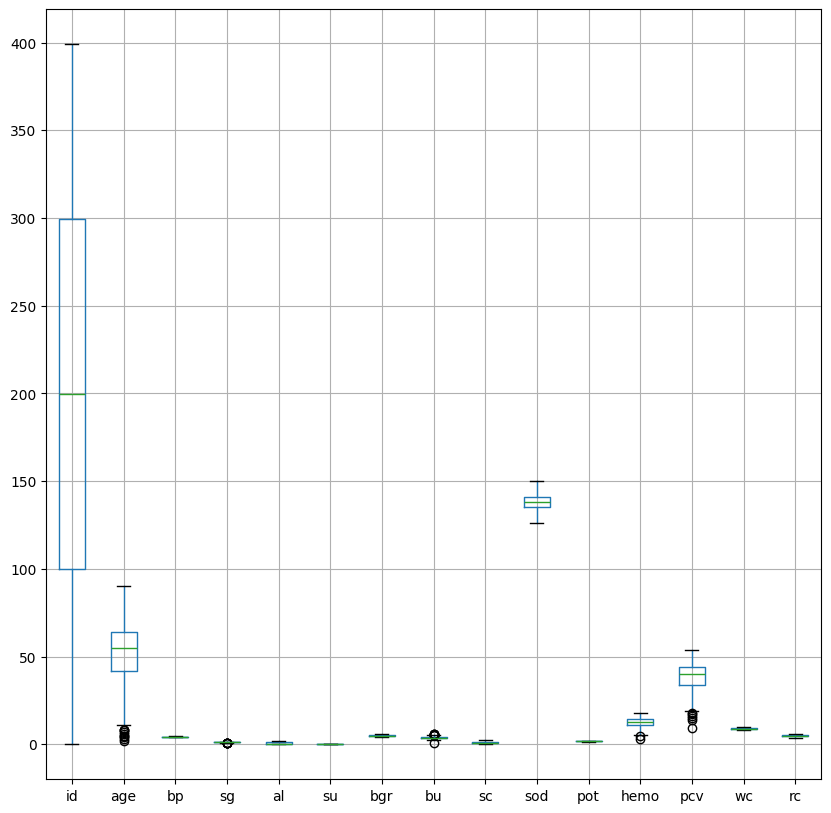

In [113]:
df.boxplot(figsize=(10,10))

In [114]:
correlation = df.corr(numeric_only=True)

print(correlation)

            id       age        bp        sg        al  su       bgr  \
id    1.000000 -0.186274 -0.259637  0.582504 -0.514492 NaN -0.330777   
age  -0.186274  1.000000  0.142777 -0.160374  0.114278 NaN  0.275628   
bp   -0.259637  0.142777  1.000000 -0.194166  0.165398 NaN  0.172461   
sg    0.582504 -0.160374 -0.194166  1.000000 -0.515397 NaN -0.339388   
al   -0.514492  0.114278  0.165398 -0.515397  1.000000 NaN  0.320652   
su         NaN       NaN       NaN       NaN       NaN NaN       NaN   
bgr  -0.330777  0.275628  0.172461 -0.339388  0.320652 NaN  1.000000   
bu   -0.331258  0.278907  0.192010 -0.262833  0.364881 NaN  0.210975   
sc   -0.503926  0.271602  0.285055 -0.390345  0.431793 NaN  0.265836   
sod   0.431200 -0.106311 -0.148141  0.352375 -0.394926 NaN -0.253566   
pot  -0.056104  0.084838  0.094263  0.033023  0.055276 NaN  0.057868   
hemo  0.607231 -0.178308 -0.275675  0.490699 -0.495373 NaN -0.306286   
pcv   0.566986 -0.212796 -0.278191  0.496434 -0.493052 NaN -0.30

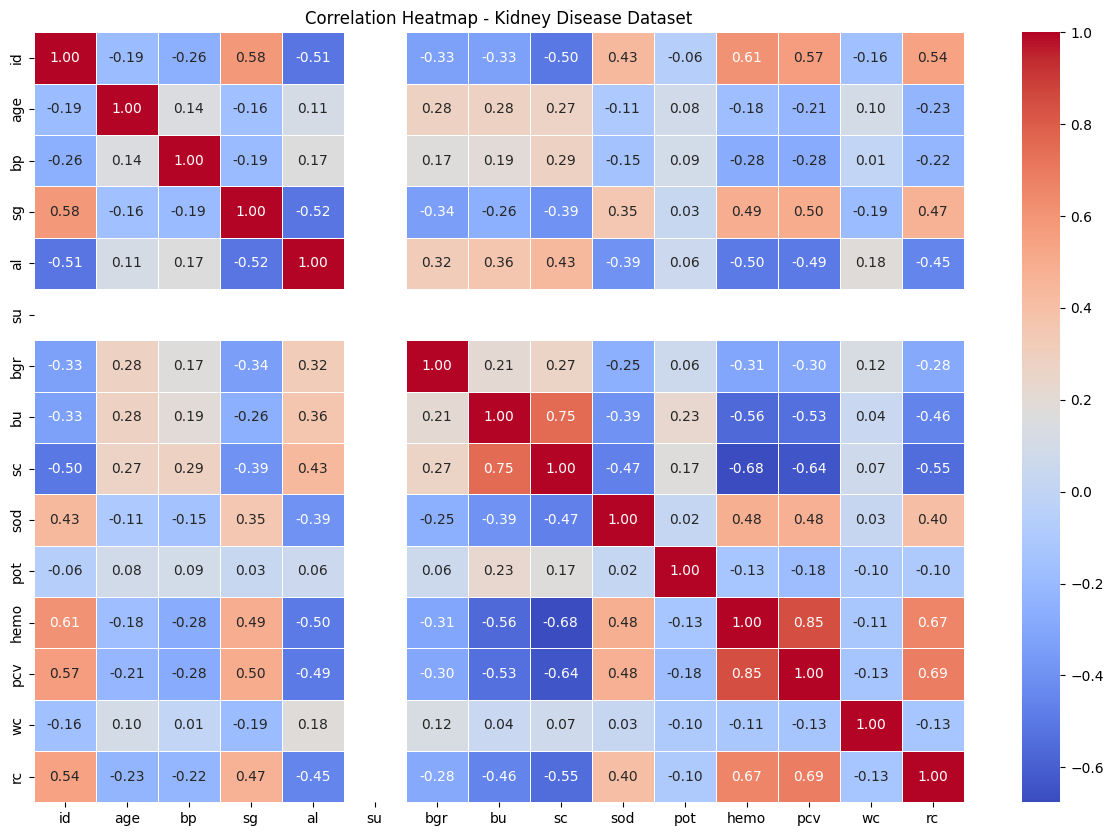

In [115]:
plt.figure(figsize=(15, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap - Kidney Disease Dataset")
plt.show()

In [116]:
df['classification'] = df['classification'].map({
    'ckd': 1,
    'notckd': 0
})

In [117]:
target_corr = df.corr(numeric_only=True)['classification'].sort_values(
    ascending=False
)

print(target_corr)

classification    1.000000
sc                0.595479
al                0.577666
bgr               0.424662
bu                0.400347
bp                0.304594
age               0.227842
wc                0.177824
pot               0.055417
sod              -0.498441
rc               -0.612467
sg               -0.659504
pcv              -0.673129
hemo             -0.726368
id               -0.838528
su                     NaN
Name: classification, dtype: float64


In [118]:
print("Features with correlation greater than 0.5:")

print(target_corr[
    (target_corr > 0.5) | (target_corr < -0.5)
])

Features with correlation greater than 0.5:
classification    1.000000
sc                0.595479
al                0.577666
rc               -0.612467
sg               -0.659504
pcv              -0.673129
hemo             -0.726368
id               -0.838528
Name: classification, dtype: float64


In [119]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

In [120]:
cat_cols = df.select_dtypes(include=['object']).columns

print("Categorical Columns:")
print(list(cat_cols))

Categorical Columns:
['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


In [121]:
le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

In [122]:
df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,4.394449,1.020,0.693147,0.0,1,1,0,0,...,44.0,8.962007,5.2,1,1,0,0,0,0,1
1,1,7.0,4.065026,1.020,1.609438,0.0,1,1,0,0,...,38.0,8.699681,4.8,0,0,0,0,0,0,1
2,2,62.0,4.394449,1.010,1.098612,0.0,1,1,0,0,...,31.0,8.922792,4.8,0,1,0,1,0,1,1
3,3,48.0,4.262680,1.005,1.609438,0.0,1,0,1,0,...,32.0,8.810012,3.9,1,0,0,1,1,1,1
4,4,51.0,4.394449,1.010,1.098612,0.0,1,1,0,0,...,35.0,8.895767,4.6,0,0,0,0,0,0,1


In [123]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale the data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Training data: (320, 24)
Testing data: (80, 24)


In [124]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report

# Create the models
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train and evaluate each model
for name, model in models.items():

    # Train the model
    model.fit(X_train_scaled, y_train)

    # Predict on test data
    y_pred = model.predict(X_test_scaled)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))


Model: Decision Tree
Accuracy: 96.25 %

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.95        30
           1       0.98      0.96      0.97        50

    accuracy                           0.96        80
   macro avg       0.96      0.96      0.96        80
weighted avg       0.96      0.96      0.96        80


Model: Logistic Regression
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        50

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80


Model: Random Forest
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      

In [125]:
# Remove the ID column and target column
X = df.drop(['id', 'classification'], axis=1)

# Target variable
y = df['classification']

print("X shape:", X.shape)
print("y shape:", y.shape)

print("Features used:")
print(X.columns.tolist())

X shape: (400, 24)
y shape: (400,)
Features used:
['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


In [126]:
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

In [127]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [128]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(
    n_neighbors=3
)

In [129]:
knn.fit(
    X_train,
    y_train
)

KNeighborsClassifier(n_neighbors=3)

In [130]:
y_pred = knn.predict(X_test)

In [131]:
print(y_pred)

[0 1 1 0 1 1 0 1 1 1 1 1 0 1 0 1 1 0 1 1 1 0 0 1 0 1 0 0 1 0 1 1 1 1 1 0 1
 1 1 1 1 1 0 0 1 0 0 1 1 0 1 0 1 1 1 0 1 0 1 1 1 1 0 0 0 1 0 0 1 1 0 1 1 0
 0 1 0 1 1 0]


In [132]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(accuracy)

0.9875


In [133]:
from sklearn.ensemble import RandomForestClassifier

In [134]:
model = RandomForestClassifier()
model.fit(X_train, y_train)

RandomForestClassifier()

In [135]:
y_pred = model.predict(X_train)

In [136]:
print(y_pred)

[1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 1 1 0 0 1 1 1 0 1 0 1 1 1 0 1 0 1 1 1
 0 1 1 1 0 1 0 0 0 0 1 0 1 1 0 1 0 0 0 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 1 0
 1 0 0 1 1 1 1 1 0 1 1 1 0 1 0 0 1 1 0 1 0 1 1 1 1 1 0 1 1 1 0 0 0 0 1 0 1
 1 0 0 1 1 1 1 1 1 1 0 1 0 1 0 1 1 1 0 0 1 0 1 1 0 1 1 1 0 0 0 1 0 0 1 1 1
 1 0 1 1 0 1 0 1 0 0 1 1 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 0 1 1 0 0 1
 1 1 0 0 0 0 0 1 0 0 1 1 0 0 0 0 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0
 0 0 0 0 1 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 0 0 0 1 1 1 1 1 1 1 1 1 0 1 1 1 1
 1 0 1 1 0 1 0 1 1 1 0 0 0 1 0 1 0 1 1 1 1 1 0 1 1 1 1 0 1 1 1 0 1 1 1 0 1
 1 0 0 0 0 0 1 0 0 1 1 1 1 0 1 1 1 0 1 1 0 1 1 0]


In [137]:
from sklearn.metrics import accuracy_score

# Predict on the test set instead of the training set
y_pred = model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(accuracy)

1.0


In [138]:
from sklearn.linear_model import LogisticRegression
log_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)
log_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [139]:
y_pred = log_model.predict(X_test)

In [140]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 1.0


In [141]:
from sklearn.tree import DecisionTreeClassifier

In [142]:
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    random_state=42
)

In [143]:
model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [144]:
y_pred = model.predict(X_test)

In [145]:
print(y_pred)

[0 1 1 0 1 1 0 1 0 1 1 1 1 1 0 1 1 0 1 1 1 0 0 1 0 1 0 1 1 0 1 1 1 1 1 0 1
 1 1 1 1 1 0 0 1 0 0 1 1 0 1 0 1 1 1 0 1 0 1 0 1 1 0 0 0 1 0 0 1 1 0 1 1 0
 0 1 0 1 1 0]


In [146]:
accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Decision Tree Accuracy: 0.9625
Accuracy Percentage: 96.25
